# FoodWise — Model Training Notebook

**Purpose:** Train and evaluate a pre-meal food-waste prediction model using the updated historical features.

This notebook keeps `Actual` attendance in the historical dataset for deriving past records and auditing, but **does not use current `Actual` attendance as a model input**.



## 1. Import libraries

In [5]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import joblib

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the updated dataset

In [6]:
candidate_paths = [
    Path("data/FoodWise_Updated_Dataset.xlsx"),
    Path("FoodWise_Updated_Dataset.xlsx"),
    Path("../data/FoodWise_Updated_Dataset.xlsx"),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find FoodWise_Updated_Dataset.xlsx. "
        "Place it in ./data/ or beside this notebook."
    )

df = pd.read_excel(DATA_PATH, sheet_name="Mess Data")
df["Date"] = pd.to_datetime(df["Date"], errors="raise")
df = df.sort_values(["Date", "Meal"], kind="stable").reset_index(drop=True)

print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
display(df.head())

Loaded: data/FoodWise_Updated_Dataset.xlsx
Shape: (1000, 12)
Date range: 2025-08-01 to 2026-04-07


,Date,Day,Meal,Menu,Expected,Actual,Prepared kg,Waste kg,Previous Waste kg,Remark,Previous Attendance (Same Menu),Previous Waste (Same Menu)
0,2025-08-01,Friday,Breakfast,Upma + Bread + Butter + Eggs,4967,4890,1819.6,107.2,NaN,Normal day,NaN,NaN
1,2025-08-01,Friday,Dinner,Kadhai Paneer + Roti + Rice,5417,5417,2759.1,236.5,NaN,Normal day,NaN,NaN
2,2025-08-01,Friday,Lunch,Rice + Rajma + Roti + Boondi Raita,5605,5464,2789.8,164.0,NaN,Normal day,NaN,NaN
3,2025-08-01,Friday,Snacks,Maggi + Chai,5187,4898,1483.1,114.5,NaN,Normal day,NaN,NaN
4,2025-08-02,Saturday,Breakfast,Besan Chila + Chutney + Milk,4881,4193,1797.3,148.2,107.2,Weekend,NaN,NaN


## 3. Basic data-quality checks

In [7]:
required_cols = [
    "Date", "Day", "Meal", "Menu", "Expected", "Actual", "Prepared kg",
    "Waste kg", "Previous Waste kg", "Remark",
    "Previous Attendance (Same Menu)", "Previous Waste (Same Menu)"
]
missing_cols = sorted(set(required_cols) - set(df.columns))
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

print("Rows:", len(df))
print("Duplicate full rows:", int(df.duplicated().sum()))
print("\nMissing values:")
display(df[required_cols].isna().sum().rename("Missing count").to_frame())

print("\nMeal counts:")
display(df["Meal"].value_counts().rename("Rows").to_frame())

print("\nDistinct menus per meal:")
display(df.groupby("Meal")["Menu"].nunique().rename("Distinct menus").to_frame())

if (df["Waste kg"].dropna() < 0).any():
    warnings.warn("Negative target values found; inspect the data.")
if (df["Prepared kg"].dropna() < 0).any():
    warnings.warn("Negative prepared-food values found; inspect the data.")

Rows: 1000
Duplicate full rows: 0

Missing values:


,Missing count
Date,0
Day,0
Meal,0
Menu,0
Expected,0
Actual,0
Prepared kg,0
Waste kg,0
Previous Waste kg,4
Remark,0



Meal counts:


,Rows
Meal,
Breakfast,250
Dinner,250
Lunch,250
Snacks,250



Distinct menus per meal:


,Distinct menus
Meal,
Breakfast,10
Dinner,12
Lunch,11
Snacks,11


## 4. Verify historical features

For each row, this check independently recomputes the most recent **strictly earlier date** with the same `Meal` and `Menu`. It checks that the two same-menu historical columns match that previous row.

It also checks the existing `Previous Waste kg` column against the previous record in the same meal category. This audit does not change the data.

In [8]:
audit = df.copy()
audit["Expected Previous Attendance (Same Menu)"] = np.nan
audit["Expected Previous Waste (Same Menu)"] = np.nan
audit["Expected Previous Waste kg"] = np.nan

# Calculate strictly historical values, grouping by meal and menu.
for (meal, menu), group_idx in audit.groupby(["Meal", "Menu"], sort=False).groups.items():
    idx = list(group_idx)
    idx = sorted(idx, key=lambda i: (audit.loc[i, "Date"], i))
    for pos in range(1, len(idx)):
        current_i, previous_i = idx[pos], idx[pos - 1]
        # Do not use same-date records as history if ordering is ambiguous.
        if audit.loc[previous_i, "Date"] < audit.loc[current_i, "Date"]:
            audit.loc[current_i, "Expected Previous Attendance (Same Menu)"] = audit.loc[previous_i, "Actual"]
            audit.loc[current_i, "Expected Previous Waste (Same Menu)"] = audit.loc[previous_i, "Waste kg"]

# Existing Previous Waste kg: previous chronological row within each meal category.
for meal, group_idx in audit.groupby("Meal", sort=False).groups.items():
    idx = list(group_idx)
    idx = sorted(idx, key=lambda i: (audit.loc[i, "Date"], i))
    for pos in range(1, len(idx)):
        current_i, previous_i = idx[pos], idx[pos - 1]
        if audit.loc[previous_i, "Date"] < audit.loc[current_i, "Date"]:
            audit.loc[current_i, "Expected Previous Waste kg"] = audit.loc[previous_i, "Waste kg"]

def mismatch_count(actual, expected, tol=1e-8):
    both = actual.notna() & expected.notna()
    mismatches = int((actual[both] - expected[both]).abs().gt(tol).sum())
    missingness_mismatch = int((actual.isna() != expected.isna()).sum())
    return mismatches, missingness_mismatch

checks = []
for actual_col, expected_col in [
    ("Previous Attendance (Same Menu)", "Expected Previous Attendance (Same Menu)"),
    ("Previous Waste (Same Menu)", "Expected Previous Waste (Same Menu)"),
    ("Previous Waste kg", "Expected Previous Waste kg"),
]:
    mm, miss_mm = mismatch_count(audit[actual_col], audit[expected_col])
    checks.append({
        "Feature": actual_col,
        "Value mismatches": mm,
        "Missingness mismatches": miss_mm,
        "Status": "PASS" if mm == 0 and miss_mm == 0 else "REVIEW"
    })

history_check_df = pd.DataFrame(checks)
display(history_check_df)

if (history_check_df["Status"] != "PASS").any():
    print("WARNING: One or more historical-feature checks need review before relying on the model.")
else:
    print("All historical feature checks passed.")

,Feature,Value mismatches,Missingness mismatches,Status
0,Previous Attendance (Same Menu),0,0,PASS
1,Previous Waste (Same Menu),0,0,PASS
2,Previous Waste kg,0,0,PASS


All historical feature checks passed.


## 5. Exploratory analysis

,count,mean,std,min,25%,50%,75%,max
Expected,1000.0,5446.065000,431.721862,4300.0,5130.000,5417.00,5804.500,6400.0
Actual,1000.0,5060.942000,589.566455,3206.0,4704.500,5104.00,5510.250,6385.0
Prepared kg,1000.0,2273.968600,617.445067,1207.6,1649.800,2248.45,2880.000,3355.4
Waste kg,1000.0,202.836900,96.873706,33.7,131.325,185.65,254.925,762.9
Previous Waste kg,996.0,202.606325,96.702818,33.7,131.000,185.40,254.925,762.9
Previous Attendance (Same Menu),956.0,5057.964435,589.791621,3206.0,4704.500,5104.50,5509.000,6279.0
Previous Waste (Same Menu),956.0,202.977720,97.096802,33.7,131.625,185.65,254.275,762.9


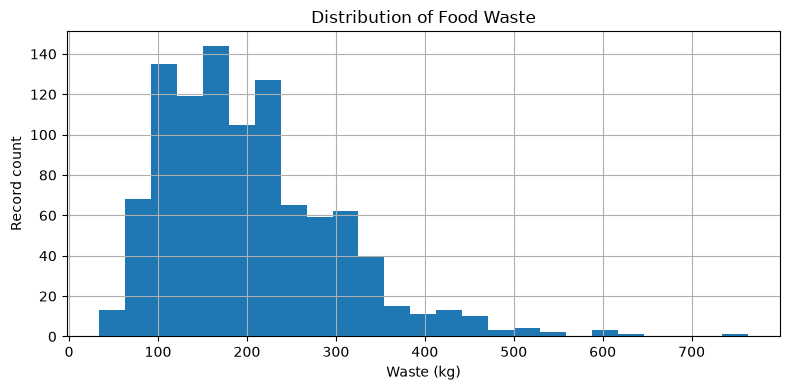

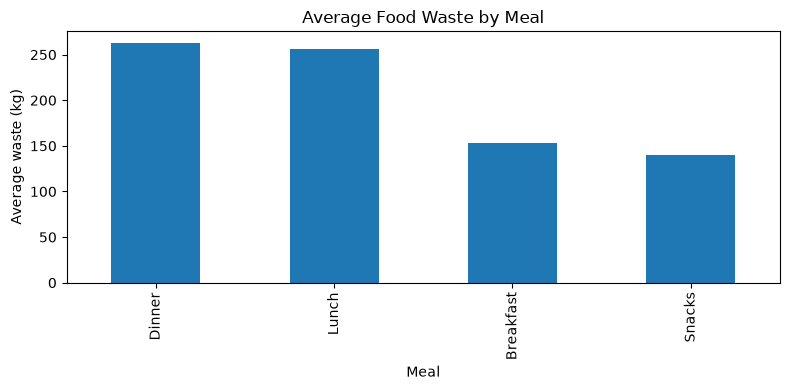

In [9]:
display(df[["Expected", "Actual", "Prepared kg", "Waste kg",
            "Previous Waste kg", "Previous Attendance (Same Menu)",
            "Previous Waste (Same Menu)"]].describe().T)

plt.figure(figsize=(8, 4))
df["Waste kg"].dropna().hist(bins=25)
plt.title("Distribution of Food Waste")
plt.xlabel("Waste (kg)")
plt.ylabel("Record count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
df.groupby("Meal")["Waste kg"].mean().sort_values(ascending=False).plot(kind="bar")
plt.title("Average Food Waste by Meal")
plt.xlabel("Meal")
plt.ylabel("Average waste (kg)")
plt.tight_layout()
plt.show()

## 6. Define prediction features

The model inputs are information intended to be available before food preparation:
- Meal, Menu, Expected attendance
- Previous attendance for the same menu
- Planned food quantity (`Prepared kg`)
- Previous meal-category waste (`Previous Waste kg`)
- Previous same-menu waste
- Remark and Day

`Actual` is intentionally excluded from `feature_cols`. `Waste kg` is the target.
Missing historical features are imputed inside the pipeline using statistics learned from the training period only; no future rows are used to fill earlier historical features.

In [10]:
feature_cols = [
    "Meal",
    "Menu",
    "Expected",
    "Previous Attendance (Same Menu)",
    "Prepared kg",
    "Previous Waste kg",
    "Previous Waste (Same Menu)",
    "Remark",
    "Day",
]
target_col = "Waste kg"

categorical_cols = ["Meal", "Menu", "Remark", "Day"]
numerical_cols = [
    "Expected",
    "Previous Attendance (Same Menu)",
    "Prepared kg",
    "Previous Waste kg",
    "Previous Waste (Same Menu)",
]

assert "Actual" not in feature_cols
assert target_col not in feature_cols
assert set(feature_cols).issubset(df.columns)

print("Model features:")
for col in feature_cols:
    print("-", col)
print("\nTarget:", target_col)

Model features:
- Meal
- Menu
- Expected
- Previous Attendance (Same Menu)
- Prepared kg
- Previous Waste kg
- Previous Waste (Same Menu)
- Remark
- Day

Target: Waste kg


## 7. Chronological train / validation / test split

Split by **unique dates**, not by individual rows, so records from one date do not spill across multiple partitions.

- Earliest 70% of dates: training
- Next 15% of dates: validation (choose model)
- Latest 15% of dates: final test (used once for final comparison)

This is a modest dataset, so metrics may vary. The synthetic nature of the data limits real-world conclusions.

In [11]:
dates = np.array(sorted(df["Date"].dropna().unique()))
if len(dates) < 10:
    raise ValueError("Not enough unique dates for a meaningful chronological split.")

train_cut = int(len(dates) * 0.70)
val_cut = int(len(dates) * 0.85)
train_dates = set(dates[:train_cut])
val_dates = set(dates[train_cut:val_cut])
test_dates = set(dates[val_cut:])

train_df = df[df["Date"].isin(train_dates)].copy()
val_df = df[df["Date"].isin(val_dates)].copy()
test_df = df[df["Date"].isin(test_dates)].copy()

print("Train:", len(train_df), "rows |", train_df["Date"].min().date(), "to", train_df["Date"].max().date())
print("Validation:", len(val_df), "rows |", val_df["Date"].min().date(), "to", val_df["Date"].max().date())
print("Test:", len(test_df), "rows |", test_df["Date"].min().date(), "to", test_df["Date"].max().date())

assert set(train_df["Date"]).isdisjoint(set(val_df["Date"]))
assert set(train_df["Date"]).isdisjoint(set(test_df["Date"]))
assert set(val_df["Date"]).isdisjoint(set(test_df["Date"]))

Train: 700 rows | 2025-08-01 to 2026-01-22
Validation: 148 rows | 2026-01-23 to 2026-02-28
Test: 152 rows | 2026-03-01 to 2026-04-07


## 8. Build preprocessing pipeline and candidate models

In [12]:
def make_preprocessor():
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ])
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer(transformers=[
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols),
    ])

candidate_estimators = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=8, min_samples_leaf=5, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=12, min_samples_leaf=3,
        random_state=42, n_jobs=-1
    ),
}

def make_pipeline(estimator):
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", estimator),
    ])

X_train = train_df[feature_cols].copy()
y_train = train_df[target_col].copy()
X_val = val_df[feature_cols].copy()
y_val = val_df[target_col].copy()
X_test = test_df[feature_cols].copy()
y_test = test_df[target_col].copy()

print("Pipelines ready.")

Pipelines ready.


## 9. Train candidates and select using validation MAE

In [13]:
def regression_metrics(y_true, predictions):
    return {
        "MAE (kg)": mean_absolute_error(y_true, predictions),
        "RMSE (kg)": np.sqrt(mean_squared_error(y_true, predictions)),
        "R2": r2_score(y_true, predictions),
        "Negative predictions": int((predictions < 0).sum()),
        "Predictions above planned food": int((predictions > X_val["Prepared kg"].to_numpy()).sum())
    }

validation_models = {}
validation_results = []

for name, estimator in candidate_estimators.items():
    model = make_pipeline(estimator)
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    metrics = regression_metrics(y_val, predictions)
    validation_models[name] = model
    validation_results.append({"Model": name, **metrics})

validation_results_df = pd.DataFrame(validation_results).sort_values("MAE (kg)").reset_index(drop=True)
display(validation_results_df.round(3))

best_model_name = validation_results_df.iloc[0]["Model"]
print("Selected using validation MAE:", best_model_name)

,Model,MAE (kg),RMSE (kg),R2,Negative predictions,Predictions above planned food
0,Linear Regression,54.193,70.395,0.152,0,0
1,Random Forest,56.957,73.654,0.071,0,0
2,Decision Tree,68.779,87.544,-0.312,0,0


Selected using validation MAE: Linear Regression


## 10. Final comparison on the untouched test period

The validation set chooses the model. The test period is kept separate and is used here for a final estimate of performance.

Negative predictions are counted as a diagnostic; they are not silently altered during metric calculation. A later app may display `max(0, prediction)`, but report the raw model metrics separately.

In [14]:
test_results = []
for name, estimator in candidate_estimators.items():
    # Fit each candidate on train + validation, then evaluate on the later test period.
    train_val_df = pd.concat([train_df, val_df], ignore_index=True)
    model = make_pipeline(estimator)
    model.fit(train_val_df[feature_cols], train_val_df[target_col])
    predictions = model.predict(X_test)
    test_results.append({
        "Model": name,
        "MAE (kg)": mean_absolute_error(y_test, predictions),
        "RMSE (kg)": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions),
        "Negative predictions": int((predictions < 0).sum()),
        "Predictions above planned food": int((predictions > X_test["Prepared kg"].to_numpy()).sum()),
    })

test_results_df = pd.DataFrame(test_results).sort_values("MAE (kg)").reset_index(drop=True)
display(test_results_df.round(3))

print("Note: use validation MAE to choose the model; test results are for final reporting.")

,Model,MAE (kg),RMSE (kg),R2,Negative predictions,Predictions above planned food
0,Linear Regression,47.715,66.817,0.535,0,0
1,Random Forest,55.894,75.170,0.411,0,0
2,Decision Tree,61.999,83.385,0.276,0,0


Note: use validation MAE to choose the model; test results are for final reporting.


## 11. Fit the selected model and save it separately

In [15]:
# Refit the selected estimator on all currently available historical rows.
# This saved model is for the app prototype; final test metrics above remain the held-out evaluation.
selected_estimator = candidate_estimators[best_model_name]
final_model = make_pipeline(selected_estimator)
final_model.fit(df[feature_cols], df[target_col])

MODEL_PATH = Path("food_waste_model_updated.pkl")
joblib.dump(final_model, MODEL_PATH)

print("Saved:", MODEL_PATH.resolve())
print("Selected model:", best_model_name)
print("Features:", feature_cols)
print("Training rows:", len(df))

Saved: /Users/shauryagoel/Documents/Smart_Mess/food_waste_model_updated.pkl
Selected model: Linear Regression
Features: ['Meal', 'Menu', 'Expected', 'Previous Attendance (Same Menu)', 'Prepared kg', 'Previous Waste kg', 'Previous Waste (Same Menu)', 'Remark', 'Day']
Training rows: 1000


## 12. Smoke-test saved model using pre-meal inputs

In [16]:
loaded_model = joblib.load(MODEL_PATH)

example_input = pd.DataFrame([{
    "Meal": "Lunch",
    "Menu": "Rice + Rajma + Roti",
    "Expected": 5000,
    "Previous Attendance (Same Menu)": 4500,
    "Prepared kg": 2800.0,
    "Previous Waste kg": 180.0,
    "Previous Waste (Same Menu)": 210.0,
    "Remark": "Normal day",
    "Day": "Monday",
}])

example_prediction = float(loaded_model.predict(example_input)[0])
print("Example predicted waste (raw):", round(example_prediction, 2), "kg")
print("Example displayed estimate (clipped at zero):", round(max(0.0, example_prediction), 2), "kg")
print("Smoke test passed.")

Example predicted waste (raw): 284.01 kg
Example displayed estimate (clipped at zero): 284.01 kg
Smoke test passed.


## 13. Interpretation and limitations

- The target is `Waste kg`; current-row `Actual` attendance is not an input.
- Historical same-menu values are sourced only from previous occurrences.
- Missing historical values are handled inside the fitted preprocessing pipeline.
- The train/validation/test periods are chronological and date-disjoint.
- These metrics measure performance on a synthetic dataset only. They do not prove accuracy in a real university mess.
- `Prepared kg` must mean the planned quantity available at prediction time. If the operational app asks for a planned quantity, use that same meaning consistently in the training data and app.
- The saved model's expected feature names must match the app's prediction DataFrame exactly.